In [20]:
import numpy as np
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))
for gpu in tf.config.list_physical_devices("GPU"):
    print("Using accelerator:", gpu)

from sklearn.model_selection import train_test_split
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix

from tensorflow.keras.models import Sequential
#this lets me build neural network layer by layer in keras
from tensorflow.keras.layers import Dense #dense makes the final prediction
from tensorflow.keras.layers import Conv2D #conv2d extract features
from tensorflow.keras.layers import Flatten #flatter reshape kore

from tensorflow.keras.layers import MaxPool2D #maxpooling kore- size reduce
from tensorflow.keras.layers import Dropout 
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

from tensorflow.keras.utils import to_categorical #converts numerical into labels into one hot encoding format

TensorFlow: 2.10.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Using accelerator: PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')


In [21]:
import kagglehub
from pathlib import Path

# Download latest version
path = kagglehub.dataset_download("abenjelloun/breast-mri-tumor-classification-dataset")
dataset_root = Path(path)

print("Path to dataset files:", dataset_root)
print("Matching dataset folders:")
for folder in dataset_root.rglob("breast_mri_dataset_original_shape"):
    print(folder)

Path to dataset files: C:\Users\Ahnaf\.cache\kagglehub\datasets\abenjelloun\breast-mri-tumor-classification-dataset\versions\1
Matching dataset folders:
C:\Users\Ahnaf\.cache\kagglehub\datasets\abenjelloun\breast-mri-tumor-classification-dataset\versions\1\breast_mri_dataset_original_shape


In [22]:
import os
import matplotlib.pyplot as plt
from PIL import Image

# Resolve the downloaded dataset folder on local Windows or Kaggle
matches = list(dataset_root.rglob("breast_mri_dataset_original_shape"))
if matches:
    BASE_PATH = str(matches[0])
elif os.path.isdir("/kaggle/input/breast-mri-tumor-classification-dataset/breast_mri_dataset_original_shape"):
    BASE_PATH = "/kaggle/input/breast-mri-tumor-classification-dataset/breast_mri_dataset_original_shape"
else:
    raise FileNotFoundError("Could not find breast_mri_dataset_original_shape under the downloaded dataset")

splits = ['train', 'val', 'test']
classes = ['Benign', 'Malignant']

print("Dataset root:", BASE_PATH)

# Count images per split per class
print(f"{'Split':<10} {'Benign':<12} {'Malignant':<12} {'Total'}")
print("-" * 44)
for split in splits:
    counts = {}
    for cls in classes:
        folder = os.path.join(BASE_PATH, split, cls)
        counts[cls] = len(os.listdir(folder))
    total = sum(counts.values())
    print(f"{split:<10} {counts['Benign']:<12} {counts['Malignant']:<12} {total}")

Dataset root: C:\Users\Ahnaf\.cache\kagglehub\datasets\abenjelloun\breast-mri-tumor-classification-dataset\versions\1\breast_mri_dataset_original_shape
Split      Benign       Malignant    Total
--------------------------------------------
train      8413         8413         16826
val        1797         1797         3594
test       1802         1802         3604


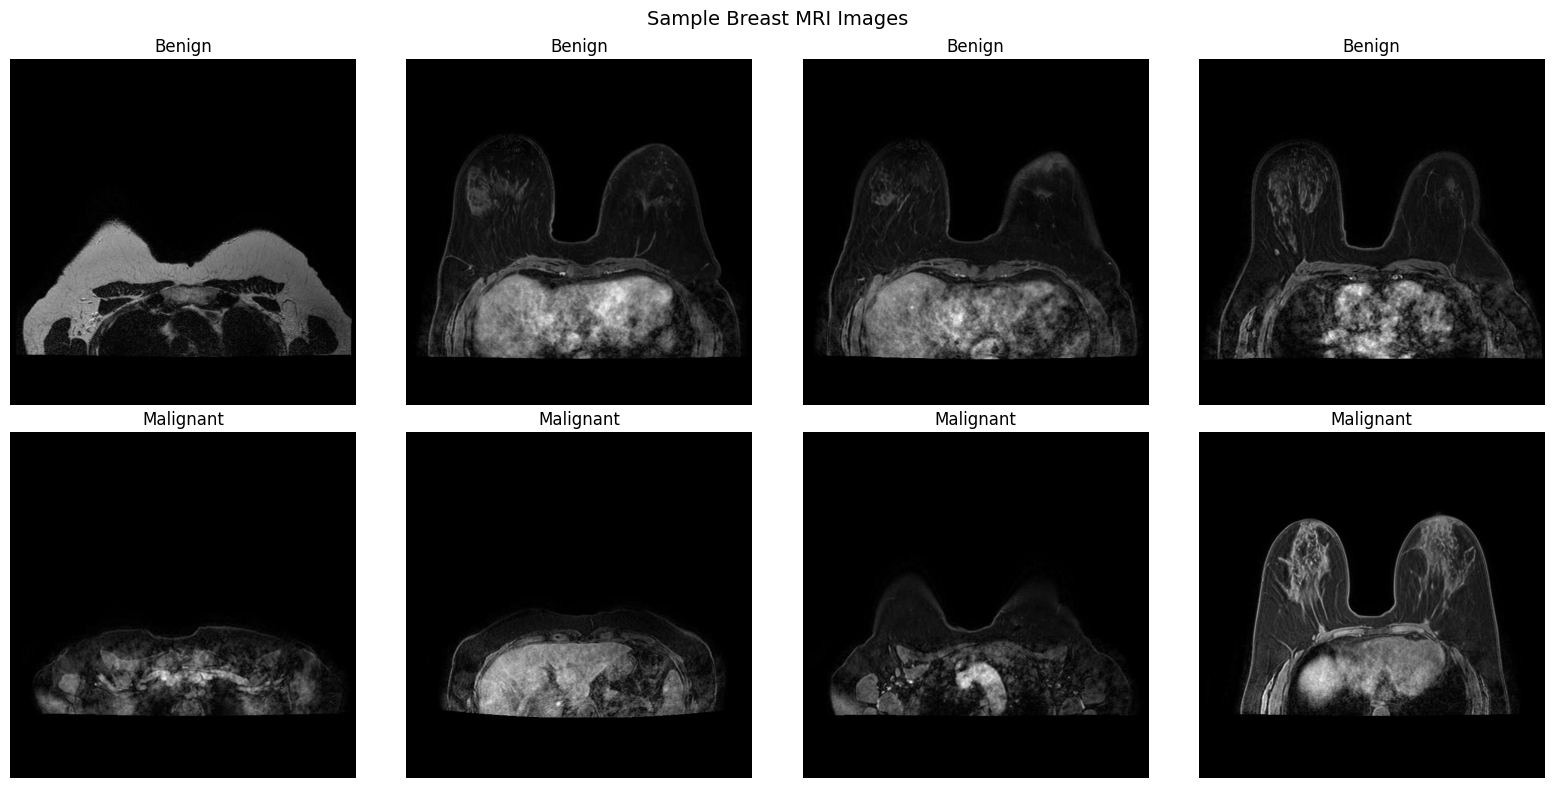

In [23]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
fig.suptitle("Sample Breast MRI Images", fontsize=14)

for row, cls in enumerate(classes):
    folder = os.path.join(BASE_PATH, 'train', cls)
    sample_imgs = os.listdir(folder)[:4]
    for col, fname in enumerate(sample_imgs):
        img = Image.open(os.path.join(folder, fname)).convert('RGB')
        axes[row][col].imshow(img, cmap='gray')
        axes[row][col].set_title(f"{cls}")
        axes[row][col].axis('off')

plt.tight_layout()
plt.show()

In [24]:
import tensorflow as tf
import os

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Create optimized datasets (images remain unscaled in 0-255 range here; model will handle scaling)
train_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(BASE_PATH, 'train'),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='binary',
    color_mode='rgb',
    shuffle=True
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(BASE_PATH, 'val'),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='binary',
    color_mode='rgb',
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(BASE_PATH, 'test'),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='binary',
    color_mode='rgb',
    shuffle=False
)

# Configure performance optimization with prefetching
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

print("Optimized tf.data Datasets ready!")

Found 16826 files belonging to 2 classes.
Found 3594 files belonging to 2 classes.
Found 3604 files belonging to 2 classes.
Optimized tf.data Datasets ready!


In [25]:
#building my cnn for medical image

CNN = Sequential([
    Conv2D(32,(3,3),activation='relu',input_shape=(224,224,3)),
    MaxPool2D(2,2),
    Conv2D(64,(3,3),activation='relu'),
    MaxPool2D(2,2),

    Conv2D(128,(3,3),activation='relu'),
    MaxPool2D(2,2),

    Flatten(),
    Dense(512,activation='relu'),
    Dropout(0.5),
    Dense(1,activation='sigmoid')
])
CNN.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_3 (Conv2D)           (None, 222, 222, 32)      896       
                                                                 
 max_pooling2d_3 (MaxPooling  (None, 111, 111, 32)     0         
 2D)                                                             
                                                                 
 conv2d_4 (Conv2D)           (None, 109, 109, 64)      18496     
                                                                 
 max_pooling2d_4 (MaxPooling  (None, 54, 54, 64)       0         
 2D)                                                             
                                                                 
 conv2d_5 (Conv2D)           (None, 52, 52, 128)       73856     
                                                                 
 max_pooling2d_5 (MaxPooling  (None, 26, 26, 128)     

In [26]:
CNN.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy',tf.keras.metrics.AUC(name='auc')] #auc for medical
)

In [ ]:
callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    ModelCheckpoint('best_breast_mri_model.h5', monitor='val_auc', save_best_only=True, mode='max'),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, verbose=1)
]

history = CNN.fit(
    train_gen,
    epochs=30,
    validation_data=val_gen,
    callbacks=callbacks
)

Epoch 1/30
343/526 [==================>...........] - ETA: 45s - loss: 0.6537 - accuracy: 0.6083 - auc: 0.6537